In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import time
from datetime import datetime

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
API_KEY = ""

CITY = "Pune"
COUNTRY = "IN"

BASE_URL = "https://api.openweathermap.org/data/2.5/weather"

NUM_RECORDS = 10

INTERVAL_SECONDS = 60

print("City:", CITY)
print("Country:", COUNTRY)
print("Number of observations:", NUM_RECORDS)

City: Pune
Country: IN
Number of observations: 10


In [3]:
def get_weather_data(city, country, api_key):
    
    params = {
        "q": f"{city},{country}",
        "appid": api_key,
        "units": "metric"
    }
    
    try:
        response = requests.get(
            BASE_URL,
            params=params,
            timeout=30
        )
        
        response.raise_for_status()
        
        return response.json()
    
    except requests.exceptions.RequestException as e:
        print("API request failed:", e)
        return None

In [4]:
def extract_weather_data(data):
    
    if data is None:
        return None
    
    if str(data.get("cod")) != "200":
        print("API Error:", data.get("message", "Unknown error"))
        return None
    
    rainfall = data.get("rain", {}).get("1h", 0)
    
    record = {
        "datetime": datetime.now(),
        "city": data["name"],
        "latitude": data["coord"]["lat"],
        "longitude": data["coord"]["lon"],
        
        "temperature_C": data["main"].get("temp", np.nan),
        "feels_like_C": data["main"].get("feels_like", np.nan),
        "min_temperature_C": data["main"].get("temp_min", np.nan),
        "max_temperature_C": data["main"].get("temp_max", np.nan),
        
        "humidity_%": data["main"].get("humidity", np.nan),
        "pressure_hPa": data["main"].get("pressure", np.nan),
        
        "wind_speed_mps": data.get("wind", {}).get("speed", np.nan),
        "wind_direction_deg": data.get("wind", {}).get("deg", np.nan),
        
        "rainfall_mm": rainfall,
        
        "weather_description": data["weather"][0].get(
            "description", ""
        )
    }
    
    return record

In [5]:
weather_records = []

print("Starting Data Collection\n")

for i in range(NUM_RECORDS):
    
    print(f"Collecting observation {i + 1}/{NUM_RECORDS}")
    
    raw_data = get_weather_data(
        CITY,
        COUNTRY,
        API_KEY
    )
    
    record = extract_weather_data(raw_data)
    
    if record is not None:
        weather_records.append(record)
        print("Data collected successfully.")
    else:
        print("Data collection failed.")
    
    if i < NUM_RECORDS - 1:
        time.sleep(INTERVAL_SECONDS)

print("\nTotal observations collected:", len(weather_records))

Starting Data Collection

Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.
Data collected successfully.

Total observations collected: 10


In [6]:
df = pd.DataFrame(weather_records)

print("\nRaw Data \n\n")
display(df)

print("\nDataset shape:", df.shape)


Raw Data 




,datetime,city,latitude,longitude,temperature_C,feels_like_C,min_temperature_C,max_temperature_C,humidity_%,pressure_hPa,wind_speed_mps,wind_direction_deg,rainfall_mm,weather_description
0,2026-08-13 21:40:31.882004,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
1,2026-08-13 21:41:32.229555,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
2,2026-08-13 21:42:32.843686,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
3,2026-08-13 21:43:33.478384,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
4,2026-08-13 21:44:33.792027,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
5,2026-08-13 21:45:34.105194,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
6,2026-08-13 21:46:34.613281,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
7,2026-08-13 21:47:35.041251,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
8,2026-08-13 21:48:35.455925,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
9,2026-08-13 21:49:35.977795,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds



Dataset shape: (10, 14)


In [7]:
if df.empty:
    raise ValueError("No weather data was collected.")

df["datetime"] = pd.to_datetime(df["datetime"])

numeric_columns = [
    "temperature_C",
    "feels_like_C",
    "min_temperature_C",
    "max_temperature_C",
    "humidity_%",
    "pressure_hPa",
    "wind_speed_mps",
    "wind_direction_deg",
    "rainfall_mm"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.sort_values("datetime")

df = df.drop_duplicates(
    subset=["datetime"],
    keep="first"
)

df[numeric_columns] = (
    df[numeric_columns]
    .interpolate(method="linear")
)

df[numeric_columns] = (
    df[numeric_columns]
    .ffill()
    .bfill()
)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned Data: \n")
display(df)

Missing values before cleaning:
datetime               0
city                   0
latitude               0
longitude              0
temperature_C          0
feels_like_C           0
min_temperature_C      0
max_temperature_C      0
humidity_%             0
pressure_hPa           0
wind_speed_mps         0
wind_direction_deg     0
rainfall_mm            0
weather_description    0
dtype: int64

Missing values after cleaning:
datetime               0
city                   0
latitude               0
longitude              0
temperature_C          0
feels_like_C           0
min_temperature_C      0
max_temperature_C      0
humidity_%             0
pressure_hPa           0
wind_speed_mps         0
wind_direction_deg     0
rainfall_mm            0
weather_description    0
dtype: int64

Cleaned Data: 



,datetime,city,latitude,longitude,temperature_C,feels_like_C,min_temperature_C,max_temperature_C,humidity_%,pressure_hPa,wind_speed_mps,wind_direction_deg,rainfall_mm,weather_description
0,2026-08-13 21:40:31.882004,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
1,2026-08-13 21:41:32.229555,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
2,2026-08-13 21:42:32.843686,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
3,2026-08-13 21:43:33.478384,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
4,2026-08-13 21:44:33.792027,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
5,2026-08-13 21:45:34.105194,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
6,2026-08-13 21:46:34.613281,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
7,2026-08-13 21:47:35.041251,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
8,2026-08-13 21:48:35.455925,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds
9,2026-08-13 21:49:35.977795,Pune,18.5196,73.8553,23.41,23.84,23.41,24.11,78,1010,3.94,259,0,broken clouds


In [8]:
average_temperature = df["temperature_C"].mean()
maximum_temperature = df["temperature_C"].max()
minimum_temperature = df["temperature_C"].min()

average_humidity = df["humidity_%"].mean()

average_wind_speed = df["wind_speed_mps"].mean()
maximum_wind_speed = df["wind_speed_mps"].max()

total_rainfall = df["rainfall_mm"].sum()
average_rainfall = df["rainfall_mm"].mean()

print("\n Weather Statistics: \n")

print(f"Average Temperature : {average_temperature:.2f} °C")
print(f"Maximum Temperature : {maximum_temperature:.2f} °C")
print(f"Minimum Temperature : {minimum_temperature:.2f} °C")

print(f"Average Humidity    : {average_humidity:.2f} %")

print(f"Average Wind Speed  : {average_wind_speed:.2f} m/s")
print(f"Maximum Wind Speed  : {maximum_wind_speed:.2f} m/s")

print(f"Average Rainfall    : {average_rainfall:.2f} mm")
print(f"Total Rainfall      : {total_rainfall:.2f} mm")

print("\nDescriptive Statistics: \n")

display(
    df[numeric_columns].describe()
)


 Weather Statistics: 

Average Temperature : 23.41 °C
Maximum Temperature : 23.41 °C
Minimum Temperature : 23.41 °C
Average Humidity    : 78.00 %
Average Wind Speed  : 3.94 m/s
Maximum Wind Speed  : 3.94 m/s
Average Rainfall    : 0.00 mm
Total Rainfall      : 0.00 mm

Descriptive Statistics: 



,temperature_C,feels_like_C,min_temperature_C,max_temperature_C,humidity_%,pressure_hPa,wind_speed_mps,wind_direction_deg,rainfall_mm
count,10.00,10.00,10.00,1.000000e+01,10.0,10.0,10.00,10.0,10.0
mean,23.41,23.84,23.41,2.411000e+01,78.0,1010.0,3.94,259.0,0.0
std,0.00,0.00,0.00,3.744889e-15,0.0,0.0,0.00,0.0,0.0
min,23.41,23.84,23.41,2.411000e+01,78.0,1010.0,3.94,259.0,0.0
25%,23.41,23.84,23.41,2.411000e+01,78.0,1010.0,3.94,259.0,0.0
50%,23.41,23.84,23.41,2.411000e+01,78.0,1010.0,3.94,259.0,0.0
75%,23.41,23.84,23.41,2.411000e+01,78.0,1010.0,3.94,259.0,0.0
max,23.41,23.84,23.41,2.411000e+01,78.0,1010.0,3.94,259.0,0.0


In [9]:
df["date"] = df["datetime"].dt.date

daily_weather = (
    df.groupby("date")
      .agg(
          average_temperature=("temperature_C", "mean"),
          maximum_temperature=("temperature_C", "max"),
          minimum_temperature=("temperature_C", "min"),
          average_humidity=("humidity_%", "mean"),
          average_wind_speed=("wind_speed_mps", "mean"),
          total_rainfall=("rainfall_mm", "sum")
      )
      .reset_index()
)

print("\n Daily Weather Summary: \n\n")

display(daily_weather)


 Daily Weather Summary: 




,date,average_temperature,maximum_temperature,minimum_temperature,average_humidity,average_wind_speed,total_rainfall
0,2026-08-13,23.41,23.41,23.41,78.0,3.94,0


In [10]:
df["month"] = df["datetime"].dt.to_period("M")

monthly_weather = (
    df.groupby("month")
      .agg(
          average_temperature=("temperature_C", "mean"),
          maximum_temperature=("temperature_C", "max"),
          minimum_temperature=("temperature_C", "min"),
          average_humidity=("humidity_%", "mean"),
          average_wind_speed=("wind_speed_mps", "mean"),
          total_rainfall=("rainfall_mm", "sum")
      )
      .reset_index()
)

print("\n Monthly Weather Summary: \n")

display(monthly_weather)


 Monthly Weather Summary: 



,month,average_temperature,maximum_temperature,minimum_temperature,average_humidity,average_wind_speed,total_rainfall
0,2026-08,23.41,23.41,23.41,78.0,3.94,0


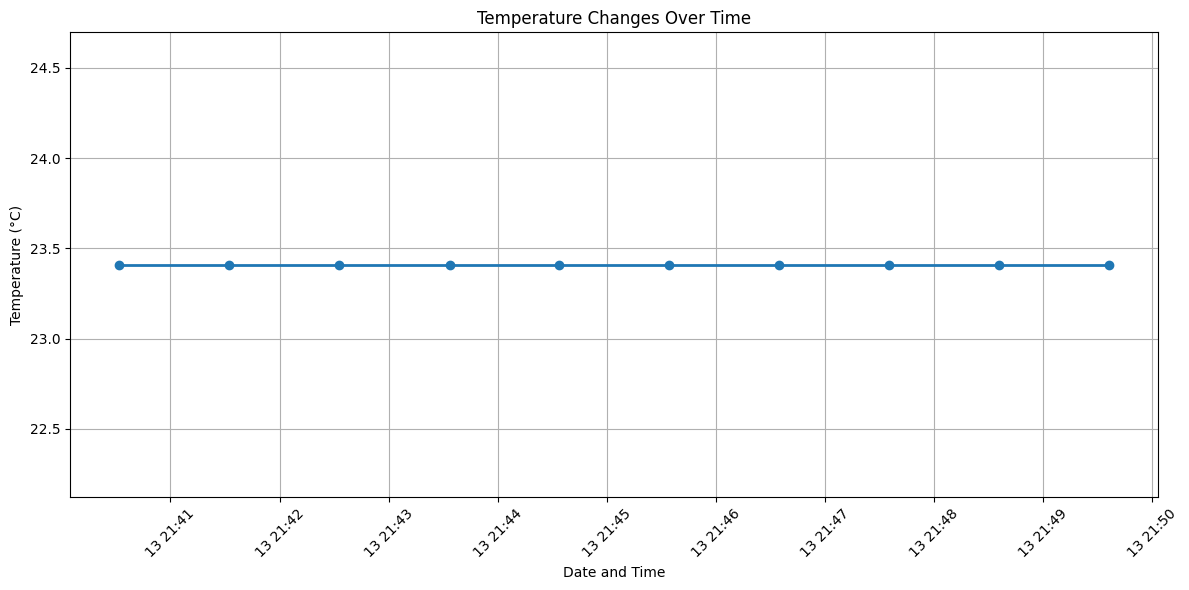

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["datetime"],
    df["temperature_C"],
    marker="o",
    linewidth=2
)

plt.title("Temperature Changes Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

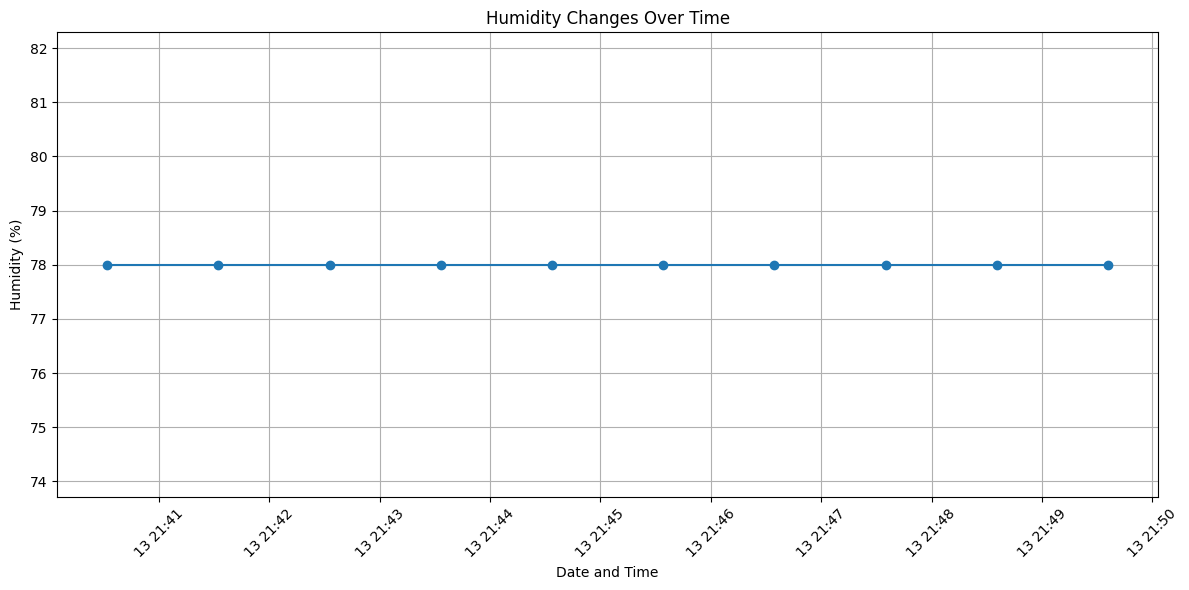

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["datetime"],
    df["humidity_%"],
    marker="o"
)

plt.title("Humidity Changes Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Humidity (%)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

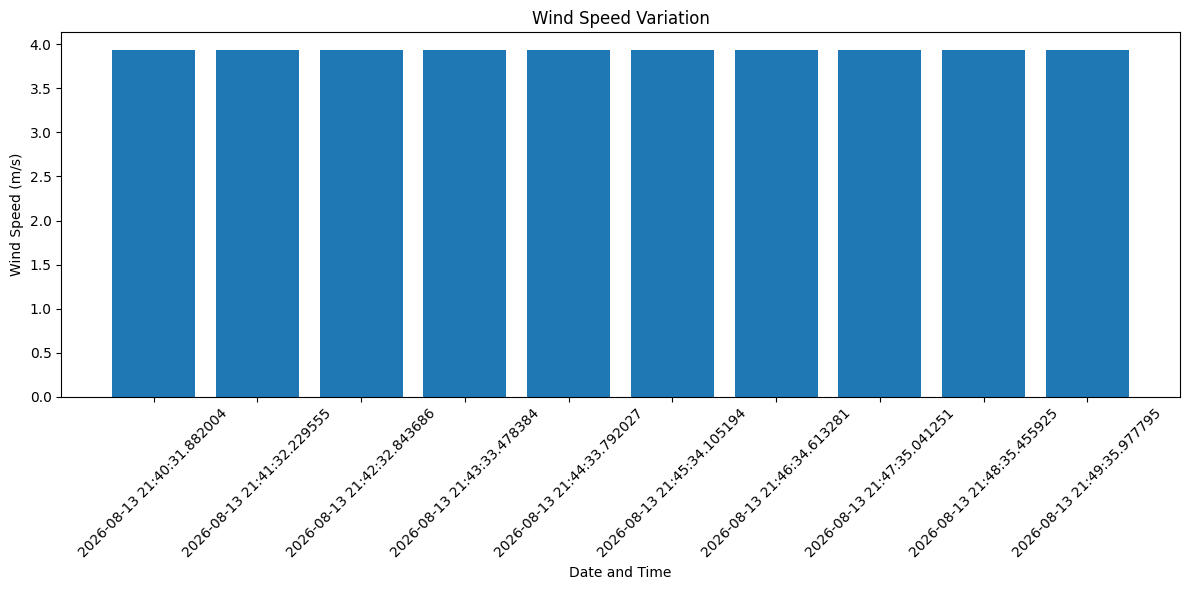

In [13]:
plt.figure(figsize=(12, 6))

plt.bar(
    df["datetime"].astype(str),
    df["wind_speed_mps"]
)

plt.title("Wind Speed Variation")
plt.xlabel("Date and Time")
plt.ylabel("Wind Speed (m/s)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

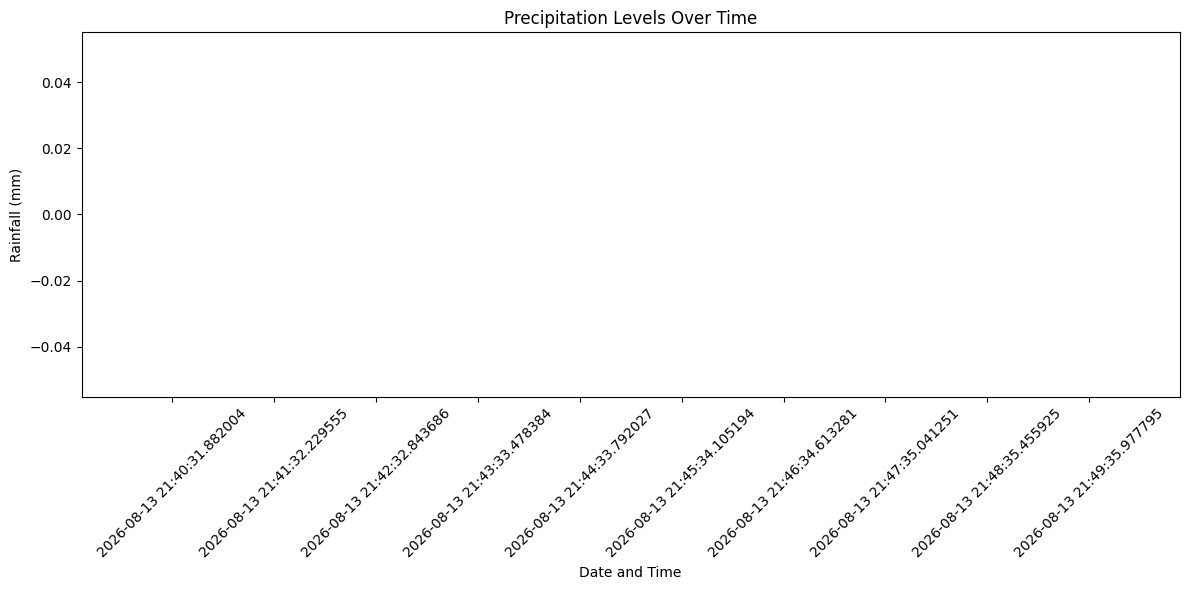

In [14]:
plt.figure(figsize=(12, 6))

plt.bar(
    df["datetime"].astype(str),
    df["rainfall_mm"]
)

plt.title("Precipitation Levels Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Rainfall (mm)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

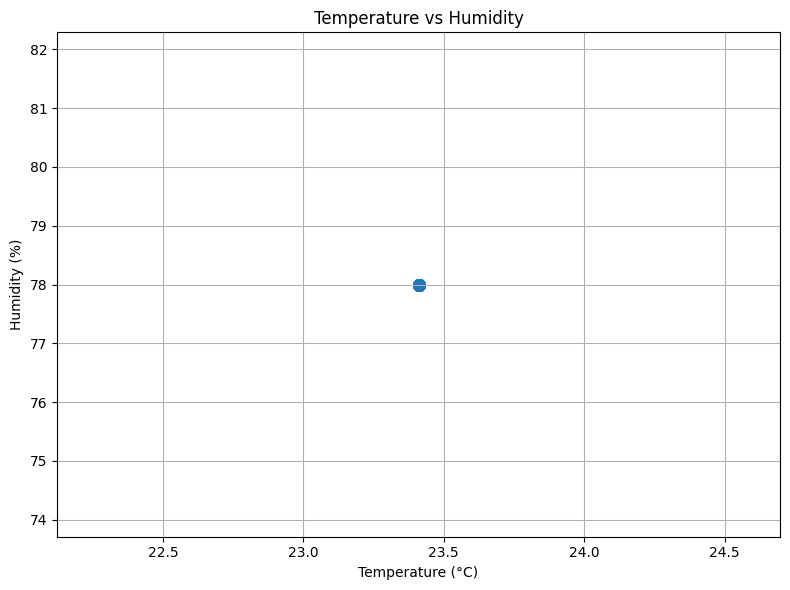

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["temperature_C"],
    df["humidity_%"],
    s=70
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")

plt.grid(True)
plt.tight_layout()

plt.show()

In [16]:
correlation_columns = [
    "temperature_C",
    "feels_like_C",
    "humidity_%",
    "pressure_hPa",
    "wind_speed_mps",
    "rainfall_mm"
]

correlation_matrix = df[
    correlation_columns
].corr()

print("\n Correlation Matrix: \n")

display(correlation_matrix)


 Correlation Matrix: 



,temperature_C,feels_like_C,humidity_%,pressure_hPa,wind_speed_mps,rainfall_mm
temperature_C,NaN,NaN,NaN,NaN,NaN,NaN
feels_like_C,NaN,NaN,NaN,NaN,NaN,NaN
humidity_%,NaN,NaN,NaN,NaN,NaN,NaN
pressure_hPa,NaN,NaN,NaN,NaN,NaN,NaN
wind_speed_mps,NaN,NaN,NaN,NaN,NaN,NaN
rainfall_mm,NaN,NaN,NaN,NaN,NaN,NaN


C:\Users\91832\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
C:\Users\91832\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


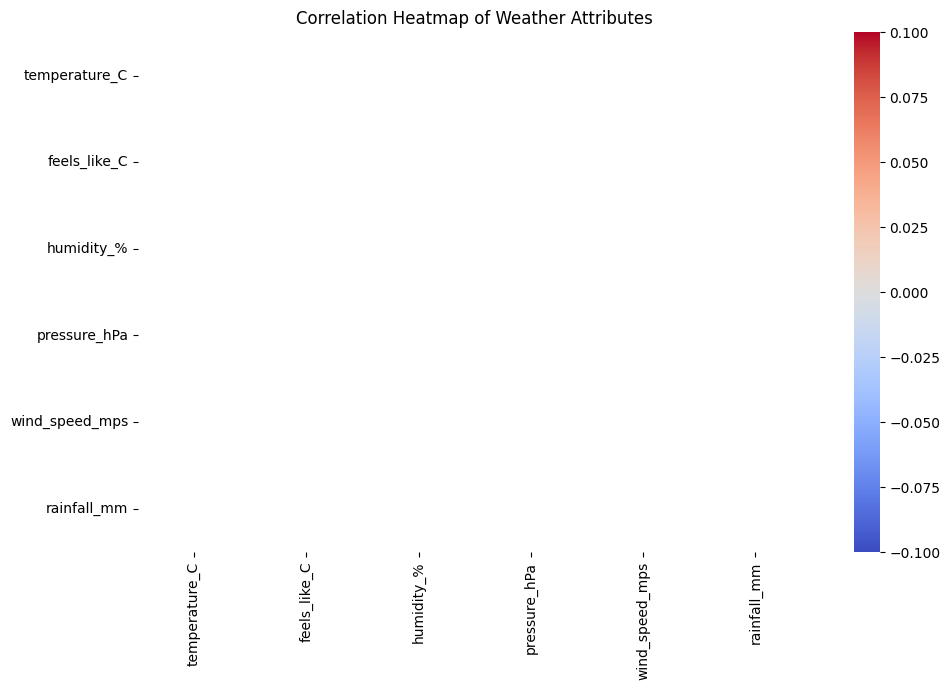

In [17]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Weather Attributes")
plt.tight_layout()

plt.show()

In [18]:
latitude = df["latitude"].iloc[0]
longitude = df["longitude"].iloc[0]

weather_map = folium.Map(
    location=[latitude, longitude],
    zoom_start=10
)

folium.Marker(
    location=[latitude, longitude],
    popup=f"""
    City: {df['city'].iloc[0]}<br>
    Temperature: {df['temperature_C'].iloc[0]:.2f} °C<br>
    Humidity: {df['humidity_%'].iloc[0]:.2f}%<br>
    Wind Speed: {df['wind_speed_mps'].iloc[0]:.2f} m/s
    """
).add_to(weather_map)

weather_map

In [ ]:
print(\n \n)
print("       OPENWEATHERMAP WEATHER ANALYSIS")
print("=" * 55)

print(f"Location              : {CITY}")
print(f"Observations          : {len(df)}")

print(
    f"Average Temperature   : "
    f"{df['temperature_C'].mean():.2f} °C"
)

print(
    f"Maximum Temperature   : "
    f"{df['temperature_C'].max():.2f} °C"
)

print(
    f"Minimum Temperature   : "
    f"{df['temperature_C'].min():.2f} °C"
)

print(
    f"Average Humidity      : "
    f"{df['humidity_%'].mean():.2f} %"
)

print(
    f"Average Wind Speed    : "
    f"{df['wind_speed_mps'].mean():.2f} m/s"
)

print(
    f"Total Rainfall        : "
    f"{df['rainfall_mm'].sum():.2f} mm"
)

print("=" * 55)
print("Analysis completed successfully!")
print("=" * 55)